# P3: 2,000-comment prototype

This quick prototype samples only the simplified **training split** with seed 42, then holds out 20% of that sample for predictions. It does not load or evaluate the dev/test splits and does not run hypothesis tests. The fixed 0.5 threshold is only for this prototype; final tuning and test evaluation are separate steps. Researcher-owned predictions and manual checks remain in `docs/user_todo.md`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import collapse_raw, hash_authors, load_emotions, load_raw, load_split
from src.metrics import add_dol, add_pol_sub, add_vulg, load_lexicon
from src.model import build_pipeline

DATA_DIR = PROJECT_ROOT / "data"
EMOTIONS = load_emotions(DATA_DIR / "simplified" / "emotions.txt")
LABEL_COLUMNS = [f"label_{emotion}" for emotion in EMOTIONS]
RANDOM_SEED = 42
SAMPLE_SIZE = 2_000

In [2]:
train = load_split(DATA_DIR / "simplified" / "train.tsv", EMOTIONS)
if len(train) < SAMPLE_SIZE:
    raise ValueError(f"Need at least {SAMPLE_SIZE} training comments; found {len(train)}")
sample = train.sample(n=SAMPLE_SIZE, random_state=RANDOM_SEED).reset_index(drop=True)

# Collapse raw rater rows for the sampled comments, removing usernames by default.
raw_comments = collapse_raw(load_raw(DATA_DIR / "raw"), EMOTIONS)
raw_comments = hash_authors(raw_comments)
sampled_comments = sample[["id"]].merge(
    raw_comments, on="id", how="left", validate="one_to_one"
)
if sampled_comments["text"].isna().any():
    raise ValueError("Some sampled training comments are missing from the raw data")

sampled_comments = add_pol_sub(sampled_comments)
sampled_comments = add_dol(sampled_comments)
sampled_comments = add_vulg(sampled_comments, load_lexicon())

print(f"Prototype sample: {len(sample):,} training comments")
print(f"Raw comment rows collapsed: {len(raw_comments):,}")
print(f"Metrics computed for sampled comments: {len(sampled_comments):,}")

Prototype sample: 2,000 training comments
Raw comment rows collapsed: 58,011
Metrics computed for sampled comments: 2,000


In [3]:
metric_summary = sampled_comments[["pol", "sub", "dol", "vulg", "vulg_any"]].describe().T
display(metric_summary)
print("Fraction with a lexicon match:", float(sampled_comments["vulg_any"].mean()))

,count,mean,std,min,25%,50%,75%,max
pol,2000.0,0.105661,0.358114,-1.0,0.0,0.0,0.316667,1.000000
sub,2000.0,0.444916,0.331569,0.0,0.1,0.5,0.700000,1.000000
dol,2000.0,12.542000,6.630627,1.0,7.0,12.0,18.000000,30.000000
vulg,2000.0,0.004917,0.027326,0.0,0.0,0.0,0.000000,0.333333
vulg_any,2000.0,0.048000,0.213820,0.0,0.0,0.0,0.000000,1.000000


Fraction with a lexicon match: 0.048


In [4]:
fit_indices, holdout_indices = train_test_split(
    np.arange(len(sample)), test_size=0.2, random_state=RANDOM_SEED
)
prototype_train = sample.iloc[fit_indices]
prototype_holdout = sample.iloc[holdout_indices]

model = build_pipeline(C=1.0, ngram_range=(1, 1))
y_train = prototype_train[LABEL_COLUMNS].to_numpy(dtype=np.int8)
y_holdout = prototype_holdout[LABEL_COLUMNS].to_numpy(dtype=np.int8)
model.fit(prototype_train["text"].tolist(), y_train)
probabilities = model.predict_proba(prototype_holdout["text"].tolist())
threshold = 0.5
predictions = (probabilities >= threshold).astype(np.int8)

prototype_macro_f1 = f1_score(
    y_holdout, predictions, average="macro", zero_division=0
)
precision, recall, per_emotion_f1, support = precision_recall_fscore_support(
    y_holdout, predictions, average=None, zero_division=0
)
prototype_metrics = pd.DataFrame(
    {
        "emotion": EMOTIONS,
        "support": support.astype(int),
        "predicted_count": predictions.sum(axis=0),
        "precision": precision,
        "recall": recall,
        "f1": per_emotion_f1,
    }
)
print(f"Fit comments: {len(prototype_train):,}; held-out comments: {len(prototype_holdout):,}")
print(f"Prototype held-out macro-F1 at threshold {threshold}: {prototype_macro_f1:.3f}")
display(prototype_metrics.sort_values("f1", ascending=False).reset_index(drop=True))

Fit comments: 1,600; held-out comments: 400
Prototype held-out macro-F1 at threshold 0.5: 0.044


,emotion,support,predicted_count,precision,recall,f1
0,gratitude,24,7,1.000000,0.291667,0.451613
1,neutral,114,30,0.666667,0.175439,0.277778
2,love,16,2,1.000000,0.125000,0.222222
3,amusement,24,2,1.000000,0.083333,0.153846
4,admiration,47,3,1.000000,0.063830,0.120000
5,approval,20,0,0.000000,0.000000,0.000000
6,confusion,12,0,0.000000,0.000000,0.000000
7,curiosity,21,0,0.000000,0.000000,0.000000
8,desire,6,0,0.000000,0.000000,0.000000
9,caring,14,0,0.000000,0.000000,0.000000


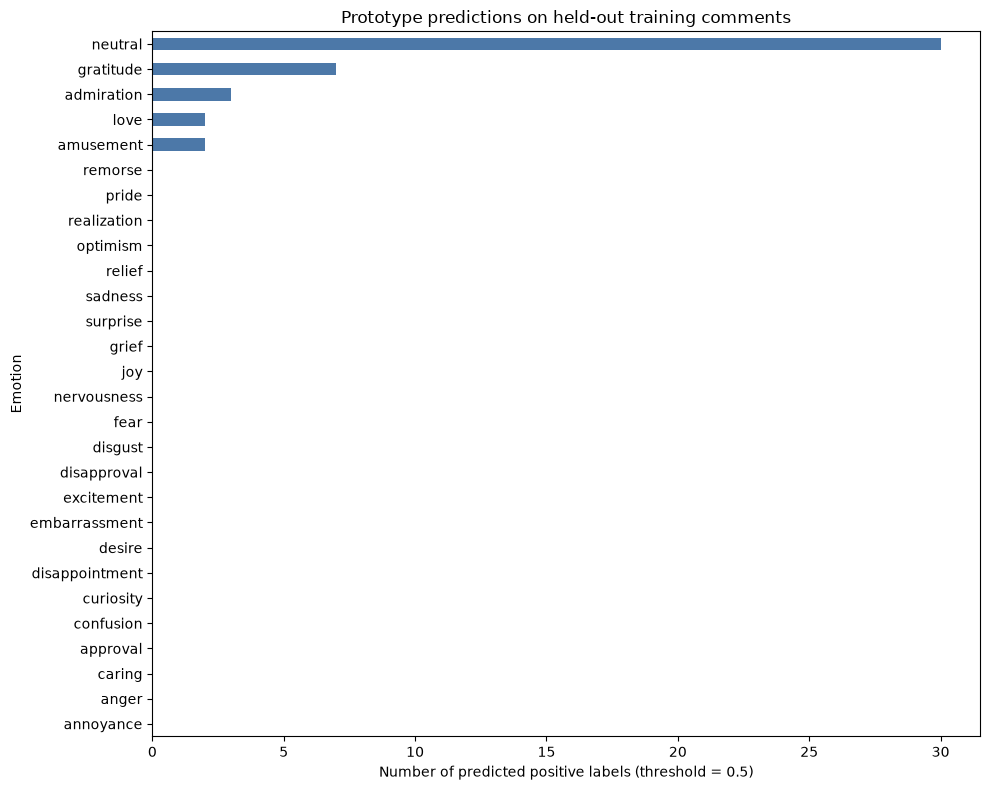

Saved prototype chart: outputs\figures\prototype_prediction_distribution.png


In [5]:
prediction_counts = pd.Series(predictions.sum(axis=0), index=EMOTIONS).sort_values()
figure, axis = plt.subplots(figsize=(10, 8))
prediction_counts.plot.barh(ax=axis, color="#4C78A8")
axis.set_title("Prototype predictions on held-out training comments")
axis.set_xlabel("Number of predicted positive labels (threshold = 0.5)")
axis.set_ylabel("Emotion")
figure.tight_layout()

figure_path = PROJECT_ROOT / "outputs" / "figures" / "prototype_prediction_distribution.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved prototype chart: {figure_path.relative_to(PROJECT_ROOT)}")

## Researcher review still required

This notebook does not complete the hand-picked TextBlob/profanity checks or choose/approve the lexicon. Fill those in yourself using `docs/metric_sanity_checks.md` and `docs/user_todo.md`. The prototype score is a quick held-out training-sample check, not the final dev-tuned or test-set result.